## Predicting a Hit

### Using Spotify audio features to determine if a song is going to "go viral"

Hello everyone and welcome to the exciting first installment of my All Things Data blog. I'm Jake Snow, your host, writer, producer, fact checker, CMO (Chief Mathematics Officer), and editor. Yeah I know, that's a lot of hats for one person to wear. I do what I can. 

It's a Saturday morning so we're going to keep this one pretty light and analyze a fun dataset I found on Kaggle (https://www.kaggle.com/datasets/vedauv/global-spotify-hits-and-audio-dynamics-20182026) - Global Spotify Hits & Audio Dynamics.

You can check out the dataset description from the link above, but to summarize we have 
* Audio features - These are a set of 5 features that Spotify uses to model songs. They include Danceability, Energy, Valence, Acousticness, and Liveness. I'd love to read some literature some day on how they compute these, but that's a topic for another day. For now we just assume that they're infallible.
* Song metadata - Not sure why the author of this dataset decided to anonymize the metadata here, would be a lot more fun if I could see the song name/artist so I could see which types of songs my model is correctly/erroneously categorizing as a "viral hit" but oh well.
* Target variables - Weeks on Top 100, total streams, is_viral_hit, longevity score. You don't really get insights into the creation of either of these more "objective" variables like viral hit or longevity score. Maybe we can discover something of their creation through our analysis.

In [1]:
import pandas as pd

In [2]:
base_path = '~/Documents/ds_projects/spotify/data/'

panel_df = pd.read_csv(base_path + 'chart_longevity_panel.csv')
audio_df = pd.read_csv(base_path + 'audio_features.csv')
meta_df = pd.read_csv(base_path + 'track_metadata.csv')

df = meta_df.merge(audio_df, on="track_id").merge(panel_df, on="track_id")

In [3]:
df.head()

,track_id,track_title,artist_name,genre,release_date,is_explicit,duration_ms,tempo_bpm,danceability,energy,valence,acousticness,liveness,musical_key,mode,peak_chart_rank,weeks_on_top_100,total_streams_mil,is_viral_hit,longevity_score
0,track_0001,Hit Song 1,Artist 164,Hip-Hop,2026-06-26,1,219088,108.8,0.775,0.331,0.838,0.488,0.006,G,Major,90,20,82.89,0,0.121
1,track_0002,Hit Song 2,Artist 29,K-Pop,2023-08-04,0,243281,115.8,0.836,0.598,0.849,0.181,0.133,A#,Minor,90,28,97.67,0,0.152
2,track_0003,Hit Song 3,Artist 7,Rock,2025-01-05,0,207916,86.3,0.395,0.874,0.398,0.043,0.439,B,Major,1,7,347.35,0,0.427
3,track_0004,Hit Song 4,Artist 190,Dance/Electronic,2022-12-16,0,172270,103.9,0.841,0.478,0.171,0.295,0.172,A#,Major,79,16,204.12,0,0.150
4,track_0005,Hit Song 5,Artist 71,Pop,2018-07-31,0,215476,139.3,0.651,0.587,0.716,0.231,0.355,G#,Minor,11,48,668.81,1,0.545


In [4]:
X = df[['is_explicit', 'duration_ms', 'tempo_bpm', 'danceability', 'energy', 'valence', 'acousticness', 'liveness', 'musical_key', 'mode']]
y = df['is_viral_hit']

## Initial Thoughts

Intuition is telling me that there isn't much here. What are some 'viral hits' that come to mind? Sure a lot of them are pop songs with similar tempos, but there are plenty of exceptions to that rule, certainly enough to throw off a model. Plus, there are millions of upbeat pop songs that didn't go viral, so how might the model make the distinction? Let's see if we can prove or disprove that intuition.

## Exploratory Data Analysis

This section is a drop-down because, spoiler alert, nothing terribly interesting gets uncovered. If you want to see some pretty graphs of data feature distributions, take a look.  

Before looking at distributions, a quick sanity check on shape, dtypes, and missingness post-merge.

In [5]:
df.info()
print()
print("Missing values per column:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   track_id           1200 non-null   str    
 1   track_title        1200 non-null   str    
 2   artist_name        1200 non-null   str    
 3   genre              1200 non-null   str    
 4   release_date       1200 non-null   str    
 5   is_explicit        1200 non-null   int64  
 6   duration_ms        1200 non-null   int64  
 7   tempo_bpm          1200 non-null   float64
 8   danceability       1200 non-null   float64
 9   energy             1200 non-null   float64
 10  valence            1200 non-null   float64
 11  acousticness       1200 non-null   float64
 12  liveness           1200 non-null   float64
 13  musical_key        1200 non-null   str    
 14  mode               1200 non-null   str    
 15  peak_chart_rank    1200 non-null   int64  
 16  weeks_on_top_100   1200 non-null   

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
track_id,1200,1200,track_0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_title,1200,1200,Hit Song 1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist_name,1200,200,Artist 68,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genre,1200,8,Pop,318,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,1200,997,2018-04-29,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_explicit,1200.0,NaN,NaN,NaN,0.290833,0.454336,0.0,0.0,0.0,1.0,1.0
duration_ms,1200.0,NaN,NaN,NaN,210468.900833,30017.46792,88061.0,190435.5,210867.0,230727.25,297784.0
tempo_bpm,1200.0,NaN,NaN,NaN,120.019167,19.782555,59.6,107.275,119.85,132.825,198.5
danceability,1200.0,NaN,NaN,NaN,0.618941,0.186707,0.3,0.456,0.6165,0.77825,0.949
energy,1200.0,NaN,NaN,NaN,0.638119,0.197479,0.303,0.466,0.6325,0.81225,0.98


### Feature distributions — continuous

The five audio features plus `duration_ms` and `tempo_bpm`.

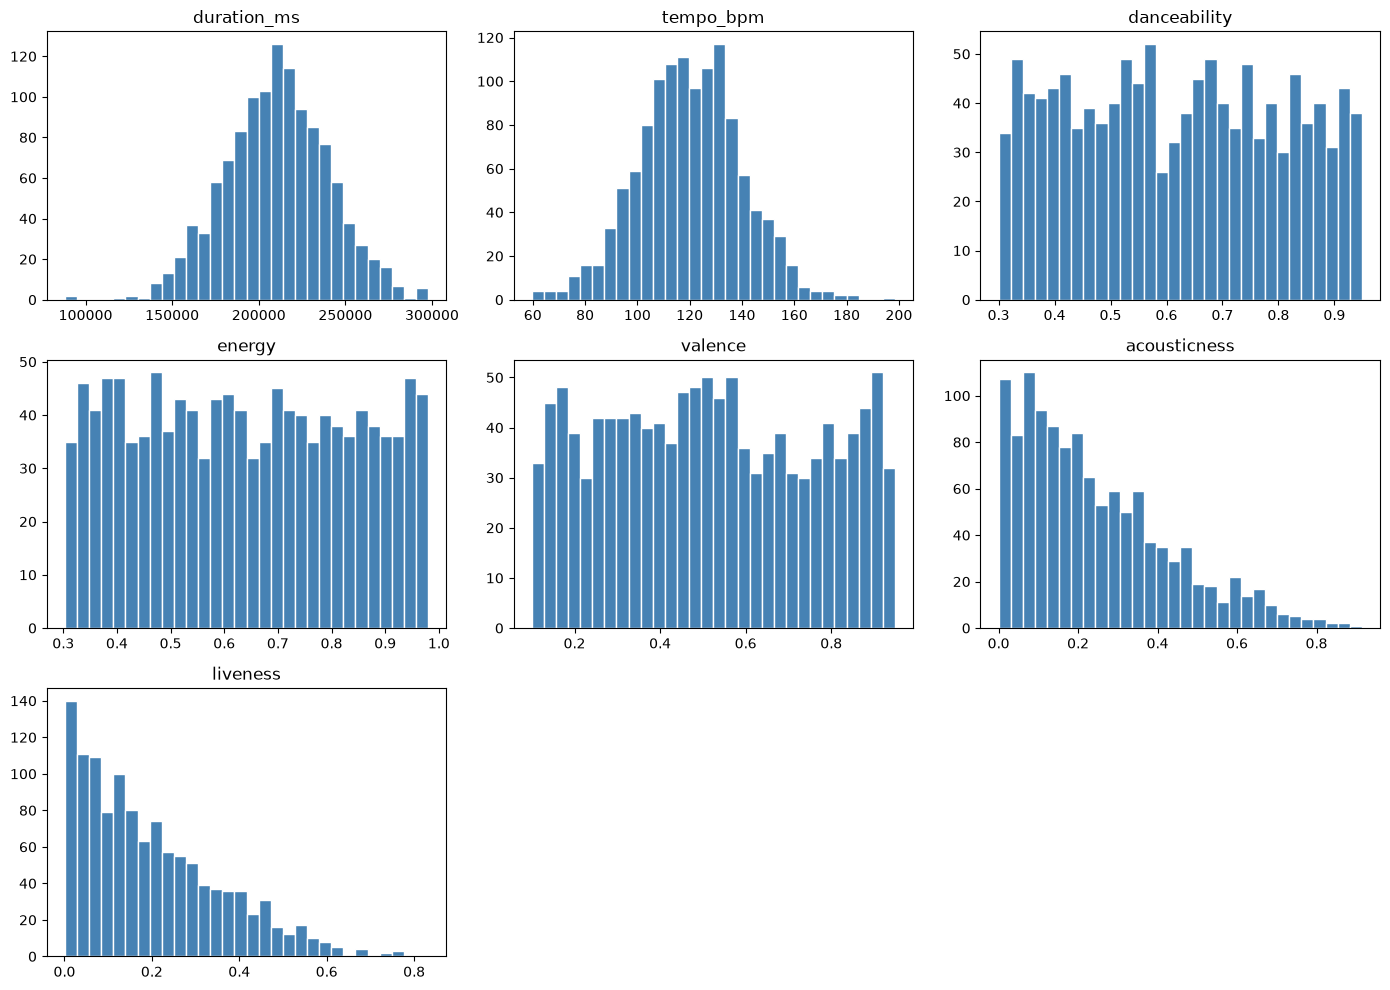

In [7]:
import matplotlib.pyplot as plt
import numpy as np

continuous_cols = ['duration_ms', 'tempo_bpm', 'danceability', 'energy', 'valence', 'acousticness', 'liveness']

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, continuous_cols):
    ax.hist(df[col], bins=30, color='steelblue', edgecolor='white')
    ax.set_title(col)
for ax in axes.flat[len(continuous_cols):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Feature distributions — categorical

`genre`, `musical_key`, `mode`, and `is_explicit` are categorical/binary, so bar charts of value counts make more sense than histograms here.

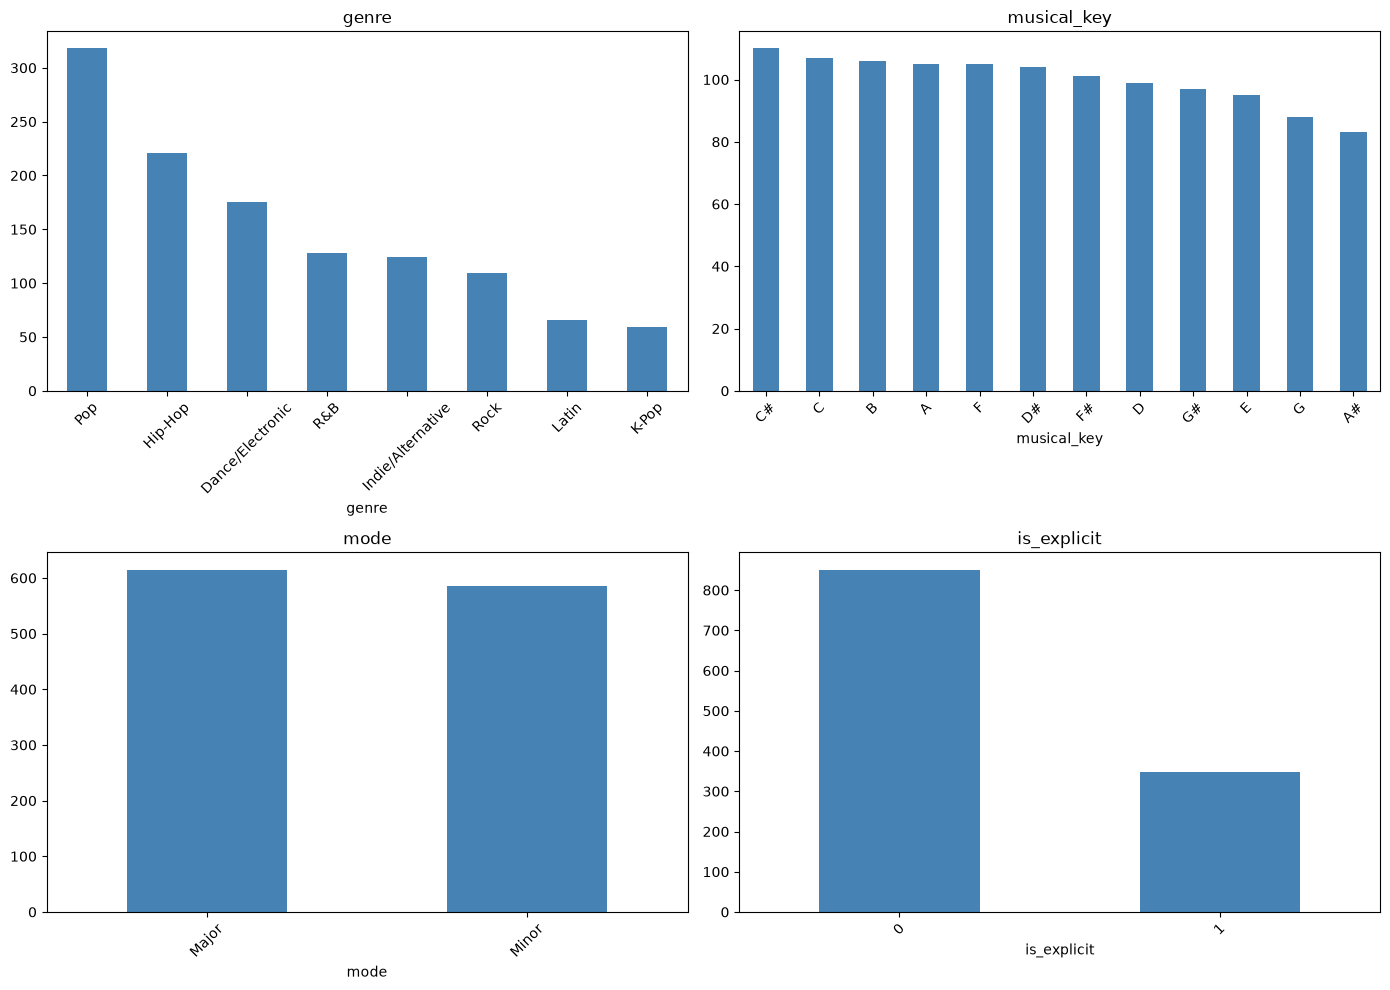

In [8]:
categorical_cols = ['genre', 'musical_key', 'mode', 'is_explicit']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, categorical_cols):
    df[col].value_counts().plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Target variable distributions

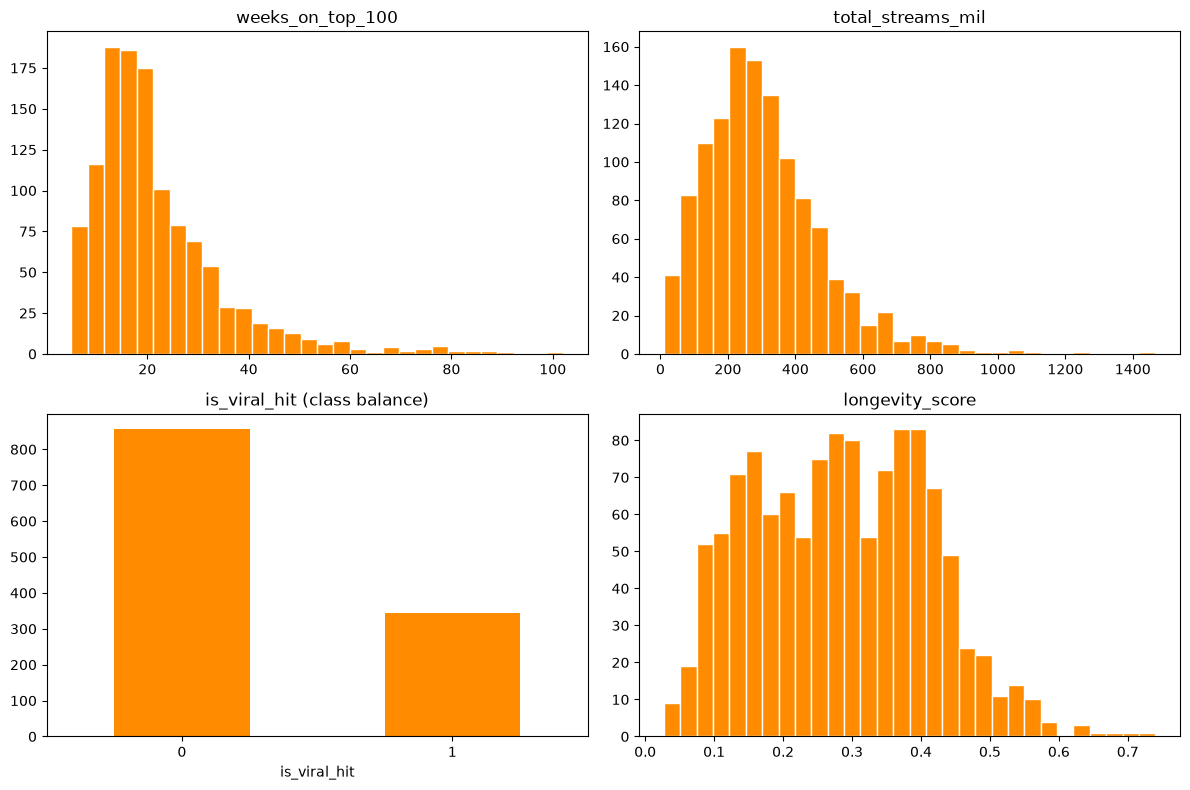

is_viral_hit
0    0.713333
1    0.286667
Name: proportion, dtype: float64


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(df['weeks_on_top_100'], bins=30, color='darkorange', edgecolor='white')
axes[0, 0].set_title('weeks_on_top_100')

axes[0, 1].hist(df['total_streams_mil'], bins=30, color='darkorange', edgecolor='white')
axes[0, 1].set_title('total_streams_mil')

df['is_viral_hit'].value_counts().plot(kind='bar', ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('is_viral_hit (class balance)')
axes[1, 0].tick_params(axis='x', rotation=0)

axes[1, 1].hist(df['longevity_score'], bins=30, color='darkorange', edgecolor='white')
axes[1, 1].set_title('longevity_score')

plt.tight_layout()
plt.show()

print(df['is_viral_hit'].value_counts(normalize=True))

## Baseline Model: Logistic Regression

Brushing off some modeling dust here so I'm starting by spinning up the simplest classifier I remember - Logistic Regression, your quintissential binary classifier. Mathematically, we're just fitting a hyperplane as our discrimenator so landing on either side of the hyperplane determines whether or not the song is a viral hit.

Let's give it a whirl.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# One hot encode my categorical columns
X_encoded = pd.get_dummies(X, columns=['musical_key', 'mode'], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)

(960, 20) (240, 20)


In [11]:
reg = LogisticRegression(random_state=42)
reg.fit(X_train, y_train)

y_pred = reg.predict(X_test)
y_proba = reg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

           0       0.71      0.98      0.82       171
           1       0.00      0.00      0.00        69

    accuracy                           0.70       240
   macro avg       0.35      0.49      0.41       240
weighted avg       0.50      0.70      0.58       240

ROC AUC: 0.4890244936011527


/Users/jakesnow/Documents/ds_projects/spotify/.spotify_venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Not included in the output above was a `ConvergenceWarning` - that's never good. Also look at that AUC score. Woof. Reminder that an AUC of .5 is a coin flip. I'm trying to drill into my head the true meaning of AUC so going to restate it here for good measure. 

To understand an AUC score, imagine taking two songs, one marked as a "viral hit" and the other not. The AUC score should be thought of as a probability that the viral hit will receive a higher predicted probability from the model than the non-hit song. More formally, 

`AUC = P(score of a randomly chosen positive example > score of a randomly chosen negative example)`

So with that context in mind, we can understand why .5 means the model is basically flipping a coin - a non-hit is just as likely to receive a higher score from the model as a hit song is. 

In regards to the `ConvergenceWarning`, I might need to adjust some model paramters. Before we do that though, I want to take a look at the model coefficients to see what our 'first pass' model learned.

In [12]:
coef_raw = pd.Series(reg.coef_[0], index=X_train.columns).sort_values(key=abs, ascending=False)
coef_raw

danceability      0.881072
valence          -0.672874
energy            0.578361
musical_key_F    -0.543603
musical_key_G#    0.543327
musical_key_C#    0.486854
mode_Minor       -0.349270
musical_key_E     0.318727
liveness         -0.312480
musical_key_F#    0.305563
musical_key_B    -0.257635
musical_key_D#    0.189137
musical_key_A#    0.153545
musical_key_D    -0.133928
musical_key_C    -0.054138
musical_key_G    -0.035439
acousticness     -0.028315
is_explicit       0.014959
tempo_bpm        -0.003455
duration_ms      -0.000005
dtype: float64

Okay so that was actually informative. `duration_ms` and `tempo_bpm` ended up with coefficients near zero (`-0.000005` and `-0.003` respectively). Taking a second to think about why makes it pretty obvious - I didn't scale anything! Every other feature is on a 0-1 scale except tempo and duration. That can throw thigns all out of whack, so let's fix that and check the AUC/coefs again.

### Round two: with scaling

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

reg_scaled = LogisticRegression(random_state=42)
reg_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = reg_scaled.predict(X_test_scaled)
y_proba_scaled = reg_scaled.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, y_pred_scaled))
print("ROC AUC:", roc_auc_score(y_test, y_proba_scaled))

              precision    recall  f1-score   support

           0       0.71      0.96      0.82       171
           1       0.14      0.01      0.03        69

    accuracy                           0.69       240
   macro avg       0.43      0.49      0.42       240
weighted avg       0.55      0.69      0.59       240

ROC AUC: 0.5025849648275278


In [14]:
coef_scaled = pd.Series(reg_scaled.coef_[0], index=X_train.columns).sort_values(key=abs, ascending=False)
coef_scaled

musical_key_G#    0.299980
musical_key_C#    0.287655
danceability      0.271325
musical_key_F#    0.245293
musical_key_E     0.240240
musical_key_D#    0.189447
mode_Minor       -0.182613
musical_key_A#    0.179777
valence          -0.179612
energy            0.176556
musical_key_G     0.160260
musical_key_C     0.147436
musical_key_D     0.139921
musical_key_B     0.117306
duration_ms      -0.101352
liveness         -0.095467
musical_key_F     0.035056
tempo_bpm        -0.025203
acousticness     -0.003895
is_explicit       0.000077
dtype: float64

### Check In

No more `ConvergenceWarning`, so that's a sign in the right direction. Also `duration_ms` now has a real, comparable coefficient (-0.10) instead of being near 0 so that's means our scaling fixed that issue.

But AUC is still trash. So the way I see it, this could mean a couple things. Either 
1) These features just don't predict virality (this aligns with natural intuition... there has to be more to virality than just the nature of the song right?). Maybe we need more complex features that relay data external to the song (release date, Tik Tok plays, etc?)
2) There isn't a linear relationship between these features. I would think that any complex relationship that might exist would have resulted in any amount of linear analysis, but maybe that intuition is off. Worth running a model that could pick up non-linear relationships. 

## Testing hypothesis #2: Random Forest

Let's go with a tried-and-true non-linear classifier: the Random Forest. One reason this pick is nice is because trees don't really care about scaling. This should determine if our previous problem was just a linear model being thrown at a non-linear problem.

In [15]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print("ROC AUC:", roc_auc_score(y_test, y_proba_rf))

              precision    recall  f1-score   support

           0       0.71      0.82      0.76       171
           1       0.27      0.16      0.20        69

    accuracy                           0.63       240
   macro avg       0.49      0.49      0.48       240
weighted avg       0.58      0.63      0.60       240

ROC AUC: 0.5023307059920332


In [16]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances

danceability      0.132006
energy            0.127014
tempo_bpm         0.121554
valence           0.120642
duration_ms       0.119631
acousticness      0.115655
liveness          0.108834
mode_Minor        0.020316
is_explicit       0.018131
musical_key_F     0.013643
musical_key_G#    0.012338
musical_key_B     0.011782
musical_key_E     0.010799
musical_key_D     0.010622
musical_key_C#    0.010551
musical_key_D#    0.010526
musical_key_G     0.009780
musical_key_F#    0.009694
musical_key_C     0.009287
musical_key_A#    0.007197
dtype: float64

That feels pretty conclusive to me. AUC score is still as bad as it gets, so linearity wasn't the problem. Takign a look at feature importances, we see that the Spotify-provided features are all around the same and all pretty low on the importance scale, which tells us that none of these features are providing us with much information about virality. 

## Future Work

It's lunch time so I'm going to call it a day for now. A couple things that I might add in the future:
1. Cross-validation. This should've been my jumping off point tbh. In hindsight, I'm not sure I can think of any good reason to not cross-validate...
2. I should probably do more hyperparameter tuning, but I think my intuitive assumption that we weren't going to find anything got in the way of that. But that's just bad practice, let the data speak for itself!
3. Is AUC enough? We probably want to take more metrics into account before we just write the whole dataset off
4. Throw in some noise. If my hypothesis here was correct (my features are basically noise) then adding an explicit random noise feature should look similar to my other features on importance charts.

What else would you do to improve this analysis?